<a href="https://colab.research.google.com/github/Nazarick0912/CPC353/blob/main/G04_CPC353_Assignment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CPC353 Assignment 1
## Frequent expressions in English–Malay ayam gepuk reviews

**Research question:** Which English and Malay words and phrases frequently occur in code-switched reviews of Ayam Gepuk Original, Sungai Dua, Penang?

This notebook documents descriptive corpus analysis using word frequencies, n-grams, and concordances. The supplied corpus contains 200 reviews, with 78 currently labeled code-switched. Collection took place during 2–6 November 2026. The full report provides the literature review, developed interpretation, and conclusions.






### 1. Load the corpus and check its structure

Upload the agreed CSV to Colab and confirm that `DATA_PATH` matches its filename. Run the notebook from top to bottom. The following cells check missing values, unique IDs, repeated URLs/text, ratings, and label compatibility. These checks do not independently verify source authenticity or linguistic annotation accuracy.

Four known source-link conflicts are retained in the main dataset and examined separately below. Identical short text alone is not treated as proof of duplicate collection.

In [1]:
from pathlib import Path
import pandas as pd
import re
from collections import Counter, defaultdict

DATA_PATH = Path(
    "/content/sample_data/CPC353_G04_Final_Review_Corpus.csv"
)

OUTPUT_DIR = Path("analysis_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    keep_default_na=False
)

required_columns = [
    "Review ID", "Data Origin", "Product Category",
    "Product / Eatery Name", "Source Platform", "Source URL",
    "Rating (1-5)", "Review Date", "Review Text",
    "Language Classification", "Code-Switching Type"
]

assert df.columns.tolist() == required_columns, \
    "The CSV columns do not match the agreed template."

# Preserve a copy for later checks.
original_text = df["Review Text"].copy()

print("Loaded:", DATA_PATH.name)
print("Reviews:", len(df))
display(df.head())

# Check every column for missing, empty, or whitespace-only values.
# This cell inspects the dataset without changing it.

missing_counts = df.apply(
    lambda column: (
        column.isna()
        | column.astype(str).str.strip().eq("")
    ).sum()
)

display(missing_counts.rename("Missing or empty values").to_frame())

print("Total missing or empty values:", missing_counts.sum())

Loaded: CPC353_G04_Final_Review_Corpus.csv
Reviews: 200


,Review ID,Data Origin,Product Category,Product / Eatery Name,Source Platform,Source URL,Rating (1-5),Review Date,Review Text,Language Classification,Code-Switching Type
0,REV-001,Self-Collected (Real),Ayam Gepuk,"Ayam Gepuk Original Sungai Dua, Penang",Google Reviews,https://maps.app.goo.gl/GXqZMRFTr2C68gCJ8,1,6 months ago,I’m quite disappointed with the food quality. ...,Code-switched,Intra-sentential
1,REV-002,Self-Collected (Real),Ayam Gepuk,"Ayam Gepuk Original Sungai Dua, Penang",Google Reviews,https://maps.app.goo.gl/5sXxLPesLn6jzj7L8,1,1 year ago,srsla kubis korng bg mcmni je???? I pay for 13...,Code-switched,Intra-sentential; Inter-sentential
2,REV-003,Self-Collected (Real),Ayam Gepuk,"Ayam Gepuk Original Sungai Dua, Penang",Google Reviews,https://share.google/W7iraTWGCIcoWDDYv,1,1 year ago,"Hmmmm judging from the picture, you can say it...",English,N/A
3,REV-004,Self-Collected (Real),Ayam Gepuk,"Ayam Gepuk Original Sungai Dua, Penang",Google Reviews,https://share.google/0QgUt75bNX9fwYpEV,1,1 year ago,I tak suka complain about food. But i bought t...,Code-switched,Intra-sentential; Inter-sentential
4,REV-005,Self-Collected (Real),Ayam Gepuk,"Ayam Gepuk Original Sungai Dua, Penang",Google Reviews,https://maps.app.goo.gl/skfuAanD57teeLVF9,2,1 year ago,Foods okay but lousy customer service i feel. ...,Code-switched,Intra-sentential; Inter-sentential


,Missing or empty values
Review ID,0
Data Origin,0
Product Category,0
Product / Eatery Name,0
Source Platform,0
Source URL,0
Rating (1-5),0
Review Date,0
Review Text,0
Language Classification,0


Total missing or empty values: 0


In [2]:
# Check whether any Review ID appears more than once.
# Display conflicting records without deleting or changing them.

duplicate_ids = df[
    df["Review ID"].duplicated(keep=False)
]

print("Total records:", len(df))
print("Unique Review IDs:", df["Review ID"].nunique())
print("Records with repeated IDs:", len(duplicate_ids))

if not duplicate_ids.empty:
    display(duplicate_ids)

Total records: 200
Unique Review IDs: 200
Records with repeated IDs: 0


In [3]:
# Identify records sharing the same source URL.
# Retain them all; a repeated URL does not by itself prove duplication.

url_conflicts = df[
    df["Source URL"].duplicated(keep=False)
].copy()

print("Records sharing a source URL:", len(url_conflicts))

display(
    url_conflicts[
        ["Review ID", "Source URL", "Review Text",
         "Language Classification"]
    ].sort_values(["Source URL", "Review ID"])
)

Records sharing a source URL: 4


,Review ID,Source URL,Review Text,Language Classification
53,REV-054,https://maps.app.goo.gl/cADE4T8krfMRijZB7,Semua makanan sedap okay. Smbal pedas dan lema...,Malay
63,REV-064,https://maps.app.goo.gl/cADE4T8krfMRijZB7,semua okay makanan sedap memang datang makan e...,Code-switched
65,REV-066,https://maps.app.goo.gl/dsSAJGTzU7PQWyUR8,"makanan memang sedap, service laju dan teratur.",Code-switched
77,REV-078,https://maps.app.goo.gl/dsSAJGTzU7PQWyUR8,service laju dan makanan sedap 👍🏻 harga berpat...,Code-switched


In [4]:
# Flag identical review text for inspection.
# Matching text alone does not prove that two records are duplicates.

repeated_text = df[
    df["Review Text"].duplicated(keep=False)
].copy()

print("Records sharing identical review text:", len(repeated_text))

display(
    repeated_text[
        ["Review ID", "Review Text", "Source URL"]
    ].sort_values(["Review Text", "Review ID"])
)

Records sharing identical review text: 6


,Review ID,Review Text,Source URL
145,REV-146,Sedap,https://maps.app.goo.gl/F8No1Qfg9UyjEuWLA
148,REV-149,Sedap,https://maps.app.goo.gl/fRtFw7PjbzmzMMx86
150,REV-151,Sedap,https://maps.app.goo.gl/VMbCeShpsnNAGPC39
175,REV-176,Sedap,https://maps.app.goo.gl/4GLkHh2JXk8YiSwA8
121,REV-122,sedap,https://maps.app.goo.gl/7BgUDZBUmAtwyyZD9
158,REV-159,sedap,https://maps.app.goo.gl/f4SXtwt9ZpnSiE9o7


In [5]:
# Check individual review ratings without changing the original column.
# Flag missing, nonnumeric, fractional, or out-of-range ratings.

ratings_numeric = pd.to_numeric(
    df["Rating (1-5)"],
    errors="coerce"
)

invalid_ratings = df[
    ~ratings_numeric.isin([1, 2, 3, 4, 5])
]

print("Records with invalid ratings:", len(invalid_ratings))

if not invalid_ratings.empty:
    display(invalid_ratings[["Review ID", "Rating (1-5)"]])
else:
    print("All ratings are valid whole numbers from 1 to 5.")

Records with invalid ratings: 0
All ratings are valid whole numbers from 1 to 5.


In [6]:
# Check that every language label uses an agreed category.
# Display the distribution without changing any annotations.

allowed_languages = [
    "English", "Malay", "Code-switched", "Other/uncertain"
]

invalid_languages = df[
    ~df["Language Classification"].isin(allowed_languages)
]

print("Records with invalid language labels:", len(invalid_languages))

if not invalid_languages.empty:
    display(
        invalid_languages[
            ["Review ID", "Language Classification"]
        ]
    )

language_counts = (
    df["Language Classification"]
    .value_counts()
    .reindex(allowed_languages, fill_value=0)
)

display(language_counts.rename("Reviews").to_frame())
print("Total:", language_counts.sum())

Records with invalid language labels: 0


,Reviews
Language Classification,
English,89
Malay,33
Code-switched,78
Other/uncertain,0


Total: 200


In [7]:
# Check switching-type labels against each review's language category.
# Allow multiple switching types separated by semicolons.
# This checks annotation consistency without changing any labels.

allowed_types = {
    "Intra-sentential",
    "Inter-sentential",
    "Tag switching"
}

def switching_label_is_valid(row):
    language = row["Language Classification"]
    switching_type = row["Code-Switching Type"]

    if language == "Code-switched":
        types = [
            item.strip()
            for item in switching_type.split(";")
        ]
        return all(item in allowed_types for item in types)

    if language in {"English", "Malay"}:
        return switching_type == "N/A"

    return switching_type in {"N/A", "Uncertain"}

invalid_switching = df[
    ~df.apply(switching_label_is_valid, axis=1)
]

print("Records with inconsistent switching labels:",
      len(invalid_switching))

if not invalid_switching.empty:
    display(
        invalid_switching[
            ["Review ID", "Language Classification",
             "Code-Switching Type"]
        ]
    )
else:
    print("All switching labels match the language categories.")

Records with inconsistent switching labels: 0
All switching labels match the language categories.


## 2. Prepare text and select the mixed-review subset

Keep the complete review as the collection and annotation unit. Preserve `Review Text` and create a separate analysis copy using lowercase letters and standardized apostrophes. Informal spellings and repeated letters remain unchanged.

Frequency analysis uses the code-switched subset. Tokens are counted within punctuation-delimited segments, using a practical boundary heuristic that preserves decimal points. Commas, colons, and ampersands do not create segment boundaries; consequently, adjacent tokens need contextual interpretation. Punctuation and emojis remain in original text but are not counted as tokens. The small demonstration strings are illustrative, not corpus records.


In [8]:
# Create a separate working copy for analysis.
# Retain repeated short reviews and the four known source conflicts.
# Save the original text so we can check that it remains unchanged.

df_clean = df.copy()
original_text = df["Review Text"].copy(deep=True)

print("Loaded reviews:", len(df))
print("Reviews retained:", len(df_clean))
print("Reviews removed:", len(df) - len(df_clean))
print(
    "Original text preserved:",
    df_clean["Review Text"].equals(original_text)
)

Loaded reviews: 200
Reviews retained: 200
Reviews removed: 0
Original text preserved: True


In [9]:
# Create minimally standardized text for counting expressions.
# Preserve the original Review Text column and informal spellings.

def prepare_analysis_text(text):
    return (
        text.lower()
        .replace("’", "'")
        .replace("‘", "'")
    )

df_clean["Analysis Text"] = (
    df_clean["Review Text"].apply(prepare_analysis_text)
)

display(
    df_clean[
        ["Review ID", "Review Text", "Analysis Text"]
    ].head(5)
)

print(
    "Original text preserved:",
    df_clean["Review Text"].equals(original_text)
)

,Review ID,Review Text,Analysis Text
0,REV-001,I’m quite disappointed with the food quality. ...,i'm quite disappointed with the food quality. ...
1,REV-002,srsla kubis korng bg mcmni je???? I pay for 13...,srsla kubis korng bg mcmni je???? i pay for 13...
2,REV-003,"Hmmmm judging from the picture, you can say it...","hmmmm judging from the picture, you can say it..."
3,REV-004,I tak suka complain about food. But i bought t...,i tak suka complain about food. but i bought t...
4,REV-005,Foods okay but lousy customer service i feel. ...,foods okay but lousy customer service i feel. ...


Original text preserved: True


In [10]:
# Select reviews labeled Code-switched for the main analysis.
# Use a separate copy so the full dataset remains unchanged.

mixed_df = df_clean[
    df_clean["Language Classification"].eq("Code-switched")
].copy()

print("Full dataset:", len(df_clean))
print("Code-switched subset:", len(mixed_df))

display(
    mixed_df[
        ["Review ID", "Language Classification", "Analysis Text"]
    ].head(5)
)

Full dataset: 200
Code-switched subset: 78


,Review ID,Language Classification,Analysis Text
0,REV-001,Code-switched,i'm quite disappointed with the food quality. ...
1,REV-002,Code-switched,srsla kubis korng bg mcmni je???? i pay for 13...
3,REV-004,Code-switched,i tak suka complain about food. but i bought t...
4,REV-005,Code-switched,foods okay but lousy customer service i feel. ...
6,REV-007,Code-switched,fast services and love the food. maybe boleh b...


In [11]:
# Split analysis text at sentence-ending punctuation and line breaks.
# Keep decimal points inside numbers, such as 13.90.
# This is a practical heuristic, not a complete sentence detector.

import re

boundary_pattern = re.compile(
    r"[!?\r\n…]+|(?<!\d)\.|\.(?!\d)"
)

def split_segments(text):
    return [
        segment.strip()
        for segment in boundary_pattern.split(text)
        if segment.strip()
    ]

# Illustrative example — not a collected review.
example = "ayam sedap. service lambat! harga 13.90… boleh repeat?"

print("Example:", example)
print("Segments:", split_segments(example))

Example: ayam sedap. service lambat! harga 13.90… boleh repeat?
Segments: ['ayam sedap', 'service lambat', 'harga 13.90', 'boleh repeat']


In [12]:
# Extract words, numbers, and decimal prices from one segment.
# Preserve informal spellings, internal apostrophes, and hyphens.
# Exclude punctuation and emojis from tokens without changing original text.

token_pattern = re.compile(
    r"(?:rm)?\d+(?:\.\d+)+|[^\W_]+(?:['-][^\W_]+)*",
    flags=re.UNICODE | re.IGNORECASE
)

def tokenize_segment(segment):
    return token_pattern.findall(segment)

# Illustrative example — not a collected review.
example_segment = "sedappp, ayam dia well-seasoned! it's RM13.90 👍"

print("Tokens:", tokenize_segment(example_segment))

Tokens: ['sedappp', 'ayam', 'dia', 'well-seasoned', "it's", 'RM13.90']


In [13]:
# Split each mixed review into segments, then tokenize each segment.
# Keep segments separate so future n-grams cannot cross their boundaries.
# Store the result in a new column without changing the review text.

mixed_df["Token Segments"] = mixed_df["Analysis Text"].apply(
    lambda text: [
        tokens
        for segment in split_segments(text)
        if (tokens := tokenize_segment(segment))
    ]
)

print("Mixed reviews processed:", len(mixed_df))
print(
    "Reviews with no usable tokens:",
    mixed_df["Token Segments"].apply(len).eq(0).sum()
)

# Inspect the first review's segments.
print("\nFirst review ID:", mixed_df.iloc[0]["Review ID"])

for number, tokens in enumerate(
    mixed_df.iloc[0]["Token Segments"], start=1
):
    print(f"Segment {number}:", tokens)

Mixed reviews processed: 78
Reviews with no usable tokens: 0

First review ID: REV-001
Segment 1: ["i'm", 'quite', 'disappointed', 'with', 'the', 'food', 'quality']
Segment 2: ['the', 'rice', 'had', 'a', 'burnt', 'hangus', 'smell', 'and', 'the', 'chicken', 'was', 'not', 'properly', 'fried']
Segment 3: ['could', 'you', 'please', 'look', 'into', 'this']


## 3. Count words, bigrams, and trigrams

Count individual token forms and consecutive sequences of two or three tokens within each segment. Report both total occurrences and the number of distinct reviews containing an expression. Keep review IDs for tracing n-gram results to their original contexts.

These are expressions occurring **within code-switched reviews**. An individual expression can be entirely English, entirely Malay, or a food name; frequency alone does not establish a language switch. Spelling variants remain separate in the primary counts. The final check reconciles totals with segment lengths; it validates arithmetic, not the linguistic suitability of every segment.


In [14]:
# Count individual tokens across the mixed-review subset.
# Distinct Reviews counts each review once per token,
# even when that token appears several times in the review.

from collections import Counter, defaultdict

word_counts = Counter()
word_review_ids = defaultdict(set)

for _, row in mixed_df.iterrows():
    for segment in row["Token Segments"]:
        for token in segment:
            word_counts[token] += 1
            word_review_ids[token].add(row["Review ID"])

word_results = pd.DataFrame([
    {
        "Word": word,
        "Occurrences": count,
        "Distinct Reviews": len(word_review_ids[word])
    }
    for word, count in word_counts.items()
]).sort_values(
    ["Occurrences", "Distinct Reviews", "Word"],
    ascending=[False, False, True]
).reset_index(drop=True)

display(word_results.head(20))

print("Total token occurrences:", sum(word_counts.values()))
print("Unique token forms:", len(word_counts))

,Word,Occurrences,Distinct Reviews
0,sedap,54,46
1,tak,42,27
2,sambal,36,22
3,ayam,34,22
4,i,31,9
5,and,30,17
6,service,29,23
7,the,29,8
8,makan,24,17
9,nak,23,12


Total token occurrences: 2540
Unique token forms: 944


In [15]:
# Count two-token expressions within each segment.
# Never join tokens across segment or review boundaries.
# Record total occurrences and the distinct reviews containing each bigram.

bigram_counts = Counter()
bigram_review_ids = defaultdict(set)

for _, row in mixed_df.iterrows():
    for segment in row["Token Segments"]:
        for position in range(len(segment) - 1):
            bigram = " ".join(segment[position:position + 2])

            bigram_counts[bigram] += 1
            bigram_review_ids[bigram].add(row["Review ID"])

bigram_results = pd.DataFrame([
    {
        "Bigram": bigram,
        "Occurrences": count,
        "Distinct Reviews": len(bigram_review_ids[bigram]),
        "Review IDs": "; ".join(sorted(bigram_review_ids[bigram]))
    }
    for bigram, count in bigram_counts.items()
]).sort_values(
    ["Occurrences", "Distinct Reviews", "Bigram"],
    ascending=[False, False, True]
).reset_index(drop=True)

display(bigram_results.head(20))

print("Total bigram occurrences:", sum(bigram_counts.values()))
print("Unique bigrams:", len(bigram_counts))

,Bigram,Occurrences,Distinct Reviews,Review IDs
0,ayam gepuk,10,9,REV-005; REV-041; REV-060; REV-063; REV-071; R...
1,makanan sedap,8,8,REV-045; REV-048; REV-061; REV-064; REV-069; R...
2,tak boleh,8,8,REV-036; REV-041; REV-058; REV-065; REV-072; R...
3,dine in,5,5,REV-031; REV-042; REV-047; REV-073; REV-090
4,level 1,5,5,REV-038; REV-042; REV-052; REV-117; REV-119
5,bad service,4,4,REV-009; REV-056; REV-095; REV-131
6,boleh tambah,4,4,REV-035; REV-047; REV-058; REV-105
7,first time,4,4,REV-038; REV-048; REV-058; REV-105
8,makan sini,4,4,REV-048; REV-056; REV-072; REV-104
9,memang sedap,4,4,REV-039; REV-066; REV-068; REV-075


Total bigram occurrences: 2265
Unique bigrams: 2053


In [16]:
# Count three-token expressions within each segment.
# Keep segment and review boundaries intact.
# Record occurrences, distinct-review counts, and supporting review IDs.

trigram_counts = Counter()
trigram_review_ids = defaultdict(set)

for _, row in mixed_df.iterrows():
    for segment in row["Token Segments"]:
        for position in range(len(segment) - 2):
            trigram = " ".join(segment[position:position + 3])

            trigram_counts[trigram] += 1
            trigram_review_ids[trigram].add(row["Review ID"])

trigram_results = pd.DataFrame([
    {
        "Trigram": trigram,
        "Occurrences": count,
        "Distinct Reviews": len(trigram_review_ids[trigram]),
        "Review IDs": "; ".join(sorted(trigram_review_ids[trigram]))
    }
    for trigram, count in trigram_counts.items()
]).sort_values(
    ["Occurrences", "Distinct Reviews", "Trigram"],
    ascending=[False, False, True]
).reset_index(drop=True)

display(trigram_results.head(20))

print("Total trigram occurrences:", sum(trigram_counts.values()))
print("Unique trigrams:", len(trigram_counts))

,Trigram,Occurrences,Distinct Reviews,Review IDs
0,boleh tambah nasi,2,2,REV-035; REV-047
1,first and last,2,2,REV-056; REV-065
2,first time makan,2,2,REV-038; REV-048
3,kacang tak boleh,2,2,REV-058; REV-117
4,kedai ayam gepuk,2,2,REV-060; REV-105
5,kena dengan tekak,2,2,REV-042; REV-077
6,makanan memang sedap,2,2,REV-066; REV-075
7,makanan sedap tapi,2,2,REV-069; REV-072
8,rasa sedap dan,2,2,REV-035; REV-055
9,sambal level 1,2,2,REV-038; REV-119


Total trigram occurrences: 1995
Unique trigrams: 1975


In [17]:
# Independently calculate expected totals from segment lengths.
# Each segment of length L contributes L words,
# max(L - 1, 0) bigrams, and max(L - 2, 0) trigrams.

segment_lengths = [
    len(segment)
    for segments in mixed_df["Token Segments"]
    for segment in segments
]

count_check = pd.DataFrame({
    "Analysis": ["Words", "Bigrams", "Trigrams"],
    "Expected": [
        sum(segment_lengths),
        sum(max(length - 1, 0) for length in segment_lengths),
        sum(max(length - 2, 0) for length in segment_lengths)
    ],
    "Actual": [
        sum(word_counts.values()),
        sum(bigram_counts.values()),
        sum(trigram_counts.values())
    ]
})

count_check["Matches"] = (
    count_check["Expected"] == count_check["Actual"]
)

display(count_check)
assert count_check["Matches"].all(), "Counting totals do not match."

,Analysis,Expected,Actual,Matches
0,Words,2540,2540,True
1,Bigrams,2265,2265,True
2,Trigrams,1995,1995,True


## 4. Inspect concordances and phrase contexts

Retrieve original-text matches with up to five whitespace-separated words on each side. Select `sedap` and `service` because they recur in the frequency results and allow inspection of Malay and English usage in context. A supplementary search groups only repeated-final-p variants of `sedap`, without modifying the corpus.

Inspect full reviews where needed. For example, `sedap service` may cross an attribute-list or clause boundary, whereas `service laju` can connect an English noun with a Malay description. Preview tables show only some rows; exported concordance tables retain all retrieved matches. Full interpretation belongs in the report.


In [18]:
# Retrieve keyword occurrences from original mixed-review text.
# Preserve matched spelling, review IDs, and source links.
# Show up to five whitespace-separated words on each side.

def get_concordance(pattern):
    results = []

    for _, row in mixed_df.iterrows():
        text = row["Review Text"]

        for match in re.finditer(pattern, text, flags=re.IGNORECASE):
            results.append({
                "Review ID": row["Review ID"],
                "Before": " ".join(text[:match.start()].split()[-5:]),
                "Match": match.group(),
                "After": " ".join(text[match.end():].split()[:5]),
                "Source URL": row["Source URL"]
            })

    return pd.DataFrame(
        results,
        columns=["Review ID", "Before", "Match", "After", "Source URL"]
    )

# Start with exact-form sedap, the most frequent token.
sedap_concordance = get_concordance(r"\bsedap\b")

print("Exact-form sedap occurrences:", len(sedap_concordance))
print("Distinct reviews:",
      sedap_concordance["Review ID"].nunique())

display(sedap_concordance.head(10))

Exact-form sedap occurrences: 54
Distinct reviews: 46


,Review ID,Before,Match,After,Source URL
0,REV-031,to dine in.. makanan tak,sedap,..,https://maps.app.goo.gl/Mh3RNGoYRvWhuoLW7
1,REV-032,,sedap,and good atmospehere.,https://maps.app.goo.gl/GKgtxhwHxSFWQ7FCA
2,REV-033,"Service was good, makanan always",sedap,✨,https://maps.app.goo.gl/VDGMc1MJ6BLyCVeA9
3,REV-034,,Sedap,! Always my favourite. Tolong,https://maps.app.goo.gl/L4WoQXwysm1N3Ebi8
4,REV-035,"dia sangat juicy, rempah rasa",sedap,dan sambal pula cukup kick,https://maps.app.goo.gl/1e4YjKHyciSxGgHp9
5,REV-036,berminyak tapi sambal gepuk mmg,sedap,.pedas padu tolong jgn beli,https://maps.app.goo.gl/CBvTrgjN3pvj6rHe8
6,REV-037,segi layanan pelanggan. Makanan masih,sedap,", cuma service kali ni",https://maps.app.goo.gl/Uc94HWZxMEAbZwbB9
7,REV-038,thru shopeefood. First time makan,sedap,". Suka sambal dia sedap,",https://maps.app.goo.gl/QabVLBiX1C49TMfZ7
8,REV-038,makan sedap. Suka sambal dia,sedap,", pedas (level 3), sambal",https://maps.app.goo.gl/QabVLBiX1C49TMfZ7
9,REV-039,Ayam memang,sedap,", sambal padu gila! Walaupun",https://maps.app.goo.gl/CzDfR4JBa3GHDFEA6


In [19]:
# Retrieve sedap and variants with repeated final p characters.
# Compare their counts without changing or normalizing the review text.
# This pattern covers sedap, sedapp, sedappp, etc., but not every variant.

sedap_variant_concordance = get_concordance(r"\bsedap+\b")

sedap_spelling_summary = (
    sedap_variant_concordance
    .assign(
        Spelling=sedap_variant_concordance["Match"].str.lower()
    )
    .groupby("Spelling")
    .agg(
        Occurrences=("Review ID", "size"),
        Distinct_Reviews=("Review ID", "nunique")
    )
    .sort_values("Occurrences", ascending=False)
    .reset_index()
)

display(sedap_spelling_summary)

print("Occurrences including these variants:",
      len(sedap_variant_concordance))
print("Distinct reviews including these variants:",
      sedap_variant_concordance["Review ID"].nunique())

,Spelling,Occurrences,Distinct_Reviews
0,sedap,54,46
1,sedapp,3,3
2,sedappp,2,2
3,sedapppp,2,2


Occurrences including these variants: 61
Distinct reviews including these variants: 52


In [20]:
# Retrieve every exact-form service occurrence from original text.
# Inspect how this English word appears in English and Malay contexts.
# This search excludes the separate spelling servis.

service_concordance = get_concordance(r"\bservice\b")

print("Exact-form service occurrences:", len(service_concordance))
print("Distinct reviews:",
      service_concordance["Review ID"].nunique())

display(service_concordance.head(15))

Exact-form service occurrences: 29
Distinct reviews: 23


,Review ID,Before,Match,After,Source URL
0,REV-005,Foods okay but lousy customer,service,i feel. Front desk girl,https://maps.app.goo.gl/skfuAanD57teeLVF9
1,REV-009,pregnant woman to sit. Bad,service,👎🏼,https://share.google/BSBJugauNEZS4ARgf
2,REV-033,,Service,"was good, makanan always sedap✨",https://maps.app.goo.gl/VDGMc1MJ6BLyCVeA9
3,REV-035,sambal pula cukup kick 🔥🥵.,Service,"pun tip top, cepat dan",https://maps.app.goo.gl/1e4YjKHyciSxGgHp9
4,REV-037,sayang. Kalau dia ada memang,service,tiptop. Sekarang service agak kurang,https://maps.app.goo.gl/Uc94HWZxMEAbZwbB9
5,REV-037,ada memang service tiptop. Sekarang,service,agak kurang memuaskan. Harap pihak,https://maps.app.goo.gl/Uc94HWZxMEAbZwbB9
6,REV-037,"pelanggan. Makanan masih sedap, cuma",service,kali ni agak mengecewakan. Thats,https://maps.app.goo.gl/Uc94HWZxMEAbZwbB9
7,REV-037,why saya bagi 1⭐️ untuk,service,.,https://maps.app.goo.gl/Uc94HWZxMEAbZwbB9
8,REV-041,"Ayam besar, ayam tak keras..",service,"cepat, tp kalau ramai mmg",https://maps.app.goo.gl/WMGWS9VyzgD9dfh96
9,REV-047,Aircond harap boleh tingkatkan lagi,service,. Agak panas,https://maps.app.goo.gl/Yia4NLA6Suj2WtKr6


In [21]:
# Select counted bigrams containing service as a complete token.
# Reuse existing counts so segment boundaries remain respected.
# Keep review IDs for checking each expression in context.

service_bigrams = bigram_results[
    bigram_results["Bigram"].apply(
        lambda phrase: "service" in phrase.split()
    )
].copy()

display(service_bigrams.reset_index(drop=True))

,Bigram,Occurrences,Distinct Reviews,Review IDs
0,bad service,4,4,REV-009; REV-056; REV-095; REV-131
1,sedap service,4,4,REV-051; REV-066; REV-073; REV-150
2,service laju,3,3,REV-051; REV-066; REV-078
3,customer service,3,2,REV-005; REV-092
4,service cepat,2,2,REV-041; REV-076
5,service terbaik,2,2,REV-071; REV-150
6,service was,2,2,REV-033; REV-092
7,service is,2,1,REV-090
8,the service,2,1,REV-090
9,cuma service,1,1,REV-037


In [22]:
# Inspect complete reviews containing the counted bigram sedap service.
# Check punctuation and meaning before interpreting token adjacency.

selected_ids = bigram_review_ids["sedap service"]

context_reviews = mixed_df[
    mixed_df["Review ID"].isin(selected_ids)
][["Review ID", "Review Text"]]

with pd.option_context("display.max_colwidth", None):
    display(context_reviews)

,Review ID,Review Text
50,REV-051,Food: sedap Service : laju walaupon beratoq Kedai : bersih Dan selesa
65,REV-066,"makanan memang sedap, service laju dan teratur."
72,REV-073,Sedap & service di dapur jgk cpt. Namun kerusi meja utk dine in tidak mencukupi. Mohon BO pertimbangkan utk buka kedai lebih besar memandangkan sudah viral & mendapat rmai permintaan. Semoga terus maju jaya.
149,REV-150,Good sedap service terbaik


In [23]:
# Inspect full contexts for service laju.
# Check whether each occurrence describes service speed.

selected_ids = bigram_review_ids["service laju"]

service_laju_contexts = mixed_df[
    mixed_df["Review ID"].isin(selected_ids)
][["Review ID", "Review Text"]]

with pd.option_context("display.max_colwidth", None):
    display(service_laju_contexts)

print("Distinct reviews:", len(service_laju_contexts))

,Review ID,Review Text
50,REV-051,Food: sedap Service : laju walaupon beratoq Kedai : bersih Dan selesa
65,REV-066,"makanan memang sedap, service laju dan teratur."
77,REV-078,service laju dan makanan sedap 👍🏻 harga berpatutan


Distinct reviews: 3


## 5. Check the influence of unresolved source links

REV-054/REV-064 and REV-066/REV-078 share URLs despite differing content or metadata. Retain all 200 records in the main analysis, but compare bigram counts after excluding these four records. This changes the mixed subset from 78 to 75 reviews because one of the four records is labeled Malay.

The comparison measures sensitivity to these records; it does not resolve their provenance or prove the remaining sources are correct. Describe the limitation and any material effects in the report.


In [24]:
# Check how source-conflict records affect bigram frequencies.
# Keep the main dataset intact; create comparison counts separately.

conflict_ids = {"REV-054", "REV-064", "REV-066", "REV-078"}

comparison_mixed = mixed_df[
    ~mixed_df["Review ID"].isin(conflict_ids)
]

comparison_counts = Counter()

for segments in comparison_mixed["Token Segments"]:
    for segment in segments:
        for position in range(len(segment) - 1):
            phrase = " ".join(segment[position:position + 2])
            comparison_counts[phrase] += 1

bigram_comparison = bigram_results[
    ["Bigram", "Occurrences"]
].copy()

bigram_comparison = bigram_comparison.rename(
    columns={"Occurrences": "Main Count"}
)

bigram_comparison["Without Conflicts"] = (
    bigram_comparison["Bigram"]
    .map(comparison_counts)
    .fillna(0)
    .astype(int)
)

bigram_comparison["Difference"] = (
    bigram_comparison["Main Count"]
    - bigram_comparison["Without Conflicts"]
)

print("Main mixed-review count:", len(mixed_df))
print("Comparison mixed-review count:", len(comparison_mixed))

display(bigram_comparison.head(20))

Main mixed-review count: 78
Comparison mixed-review count: 75


,Bigram,Main Count,Without Conflicts,Difference
0,ayam gepuk,10,10,0
1,makanan sedap,8,6,2
2,tak boleh,8,8,0
3,dine in,5,5,0
4,level 1,5,5,0
5,bad service,4,4,0
6,boleh tambah,4,4,0
7,first time,4,4,0
8,makan sini,4,4,0
9,memang sedap,4,3,1


In [25]:
# Display every bigram affected by excluding source-conflict records.
# Sort by the size of the change, then alphabetically.

affected_bigrams = bigram_comparison[
    bigram_comparison["Difference"] > 0
].sort_values(
    ["Difference", "Bigram"],
    ascending=[False, True]
).reset_index(drop=True)

display(affected_bigrams)

print("Number of affected bigrams:", len(affected_bigrams))

,Bigram,Main Count,Without Conflicts,Difference
0,laju dan,2,0,2
1,makanan sedap,8,6,2
2,service laju,3,1,2
3,dan makanan,1,0,1
4,dan teratur,1,0,1
5,datang makan,1,0,1
6,harga berpatutan,1,0,1
7,makan everyweek,1,0,1
8,makanan memang,2,1,1
9,memang datang,1,0,1


Number of affected bigrams: 16


### Additional contextual check

Return to the original reviews for `first time makan` to examine a mixed-language expression outside the four known source conflicts. Two matching records provide a small contextual example, not evidence of population-wide prevalence.


In [26]:
# Inspect complete contexts for the trigram first time makan.
# Check whether the English phrase first time connects to Malay makan.

selected_ids = trigram_review_ids["first time makan"]

first_time_contexts = mixed_df[
    mixed_df["Review ID"].isin(selected_ids)
][["Review ID", "Review Text"]]

with pd.option_context("display.max_colwidth", None):
    display(first_time_contexts)

print("Distinct reviews:", len(first_time_contexts))

,Review ID,Review Text
37,REV-038,"Beli gepuk set A thru shopeefood. First time makan sedap. Suka sambal dia sedap, pedas (level 3), sambal level 1 ada kacang so tak pedas sangat, ayam dia besar, panas & garing! (Brand lain goreng tak garing & jadi lembik) Will repeat! Harap branch ni kekalkan kualiti gepuk ni."
47,REV-048,"First time makan sini,cozy,makanan sedap"


Distinct reviews: 2


### Selected expressions and language composition

This table connects selected frequency results with human interpretation.
Expressions are selected to illustrate Malay, English, and mixed-language
usage within code-switched reviews; this is not an exhaustive ranking.

Counts come from the existing analysis tables. Language composition and
meaning are manually interpreted using our agreed annotation rules.

In [27]:
# Combine selected computed frequencies with manual interpretations.
# Retrieve counts and review IDs directly from existing results.
# Compare bigram counts with the source-conflict sensitivity results.

selected_expressions = [
    ("makanan sedap", "Bigram", "Malay", "Food evaluation"),
    ("bad service", "Bigram", "English", "Service evaluation"),
    ("service laju", "Bigram", "English–Malay", "Service speed"),
    ("service cepat", "Bigram", "English–Malay", "Service speed"),
    ("service terbaik", "Bigram", "English–Malay", "Service evaluation"),
    ("first time makan", "Trigram", "English–Malay",
     "First eating experience")
]

expression_rows = []

for expression, unit, language, meaning in selected_expressions:
    table = bigram_results if unit == "Bigram" else trigram_results
    result = table.loc[table[unit].eq(expression)].iloc[0]

    if unit == "Bigram":
        comparison_row = bigram_comparison.loc[
            bigram_comparison["Bigram"].eq(expression)
        ].iloc[0]

        difference = int(comparison_row["Difference"])
        note = (
            f"Occurrences fall by {difference} without source conflicts."
            if difference > 0
            else "Occurrence count unchanged without source conflicts."
        )
    else:
        note = (
            "Two supporting reviews, REV-038 and REV-048; "
            "neither is a known source-conflict record."
        )

    expression_rows.append({
        "Expression": expression,
        "Unit": unit,
        "Language Composition": language,
        "Meaning / Use": meaning,
        "Occurrences": int(result["Occurrences"]),
        "Distinct Reviews": int(result["Distinct Reviews"]),
        "Review IDs": result["Review IDs"],
        "Evidence / Limitation": note
    })

expression_summary = pd.DataFrame(expression_rows)

display(expression_summary)

,Expression,Unit,Language Composition,Meaning / Use,Occurrences,Distinct Reviews,Review IDs,Evidence / Limitation
0,makanan sedap,Bigram,Malay,Food evaluation,8,8,REV-045; REV-048; REV-061; REV-064; REV-069; R...,Occurrences fall by 2 without source conflicts.
1,bad service,Bigram,English,Service evaluation,4,4,REV-009; REV-056; REV-095; REV-131,Occurrence count unchanged without source conf...
2,service laju,Bigram,English–Malay,Service speed,3,3,REV-051; REV-066; REV-078,Occurrences fall by 2 without source conflicts.
3,service cepat,Bigram,English–Malay,Service speed,2,2,REV-041; REV-076,Occurrence count unchanged without source conf...
4,service terbaik,Bigram,English–Malay,Service evaluation,2,2,REV-071; REV-150,Occurrence count unchanged without source conf...
5,first time makan,Trigram,English–Malay,First eating experience,2,2,REV-038; REV-048,"Two supporting reviews, REV-038 and REV-048; n..."


## 6. Visualize selected results

Describe language-category counts for the full collected corpus and plot the top ten bigrams in the mixed subset. The bigram plot distinguishes occurrences from distinct-review counts. Ties use the existing ordering by frequency, distinct reviews, and alphabetical expression.

These charts describe the selected sample. Since the sampling procedure is not yet documented, do not interpret them as representative estimates for all reviewers or Penang language use.


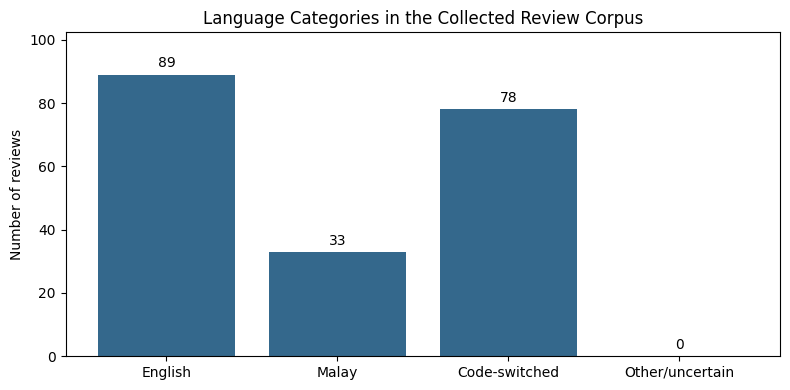

In [28]:
# Plot the language categories in the full collected dataset.
# Use current labels and display the number of reviews above each bar.

import matplotlib.pyplot as plt

categories = ["English", "Malay", "Code-switched", "Other/uncertain"]

counts = (
    df_clean["Language Classification"]
    .value_counts()
    .reindex(categories, fill_value=0)
)

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(categories, counts.values, color="#34688C")
ax.bar_label(bars, padding=3)

ax.set_title("Language Categories in the Collected Review Corpus")
ax.set_ylabel("Number of reviews")
ax.set_ylim(0, max(counts.max() * 1.15, 1))

fig.tight_layout()
plt.show()

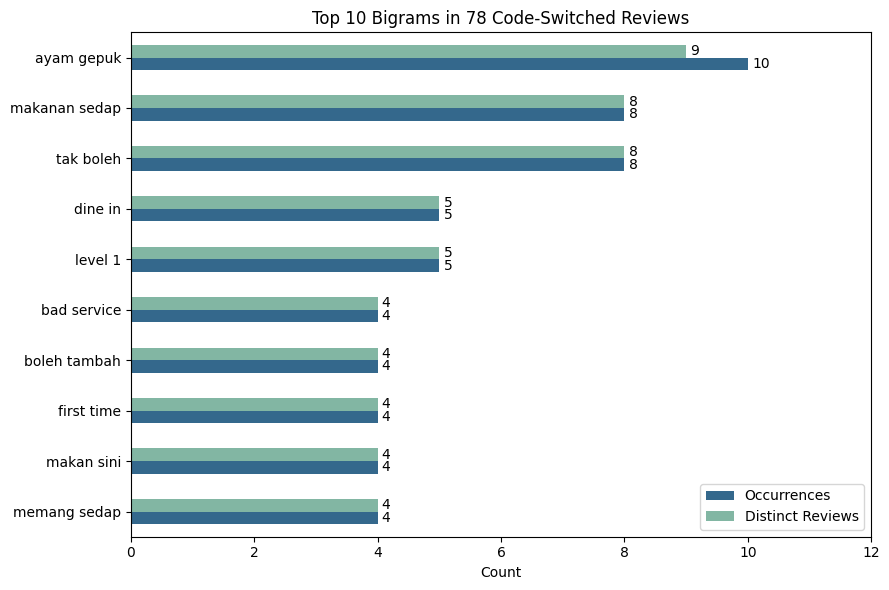

In [29]:
# Compare occurrences and distinct-review counts for the top 10 bigrams.
# Use the existing frequency ranking without changing the results.

top_bigrams = bigram_results.head(10).iloc[::-1]

ax = top_bigrams.set_index("Bigram")[
    ["Occurrences", "Distinct Reviews"]
].plot.barh(
    figsize=(9, 6),
    color=["#34688C", "#82B6A3"]
)

for bars in ax.containers:
    ax.bar_label(bars, padding=3)

ax.set_title("Top 10 Bigrams in 78 Code-Switched Reviews")
ax.set_xlabel("Count")
ax.set_ylabel("")
ax.set_xlim(0, top_bigrams["Occurrences"].max() + 2)
ax.legend(title="")

plt.tight_layout()
plt.show()

## 7. Export and verify reusable outputs

Save frequency tables, concordance evidence, the source-conflict comparison, and chart images to `analysis_outputs`. Read back CSVs to check that they match the analysis tables and verify that original review text remains unchanged. Package the outputs into a ZIP file for sharing.

The exported tables support the report; they do not replace its interpretation, verified references, annotation conventions, or limitations. Download the notebook and ZIP before ending the Colab session.


In [30]:
# Create the output folder and save each table once.
# Include the selected-expression summary alongside frequency results.

from pathlib import Path

OUTPUT_DIR = Path("analysis_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

frequency_tables = {
    "word_frequencies.csv": word_results,
    "bigram_frequencies.csv": bigram_results,
    "trigram_frequencies.csv": trigram_results,
    "selected_expression_summary.csv": expression_summary
}

for filename, table in frequency_tables.items():
    destination = OUTPUT_DIR / filename
    table.to_csv(destination, index=False, encoding="utf-8-sig")
    print(f"Saved: {destination} — {len(table)} rows")

Saved: analysis_outputs/word_frequencies.csv — 944 rows
Saved: analysis_outputs/bigram_frequencies.csv — 2053 rows
Saved: analysis_outputs/trigram_frequencies.csv — 1975 rows
Saved: analysis_outputs/selected_expression_summary.csv — 6 rows


In [31]:
# Save concordance tables and the supplementary spelling summary.
# Preserve original text excerpts and source links for interpretation.

concordance_tables = {
    "sedap_exact_concordance.csv": sedap_concordance,
    "sedap_variants_concordance.csv": sedap_variant_concordance,
    "sedap_spelling_summary.csv": sedap_spelling_summary,
    "service_concordance.csv": service_concordance
}

for filename, table in concordance_tables.items():
    destination = OUTPUT_DIR / filename
    table.to_csv(destination, index=False, encoding="utf-8-sig")
    print(f"Saved: {destination} — {len(table)} rows")

Saved: analysis_outputs/sedap_exact_concordance.csv — 54 rows
Saved: analysis_outputs/sedap_variants_concordance.csv — 61 rows
Saved: analysis_outputs/sedap_spelling_summary.csv — 4 rows
Saved: analysis_outputs/service_concordance.csv — 29 rows


In [32]:
# Save the complete comparison and the 16 affected bigrams.
# Keep these separate from the main frequency results.

comparison_tables = {
    "bigram_source_conflict_comparison.csv": bigram_comparison,
    "bigrams_affected_by_source_conflicts.csv": affected_bigrams
}

for filename, table in comparison_tables.items():
    destination = OUTPUT_DIR / filename
    table.to_csv(destination, index=False, encoding="utf-8-sig")
    print(f"Saved: {destination} — {len(table)} rows")

Saved: analysis_outputs/bigram_source_conflict_comparison.csv — 2053 rows
Saved: analysis_outputs/bigrams_affected_by_source_conflicts.csv — 16 rows


In [33]:
# Save the previously created charts as 300-dpi PNG images.
# Use tight borders so titles and labels are included.

chart_exports = {
    "language_distribution.png": fig,
    "top10_bigrams.png": ax.get_figure()
}

for filename, figure in chart_exports.items():
    destination = OUTPUT_DIR / filename
    figure.savefig(destination, dpi=300, bbox_inches="tight")
    print(f"Saved: {destination}")

Saved: analysis_outputs/language_distribution.png
Saved: analysis_outputs/top10_bigrams.png


In [34]:
# Read back exported CSVs and compare them with the analysis tables.
# Check that all reviews and their original text remain preserved.

expected_tables = {
    **frequency_tables,
    **concordance_tables,
    **comparison_tables
}

for filename, expected_table in expected_tables.items():
    saved_table = pd.read_csv(
        OUTPUT_DIR / filename,
        encoding="utf-8-sig",
        keep_default_na=False
    )

    pd.testing.assert_frame_equal(
        saved_table,
        expected_table.reset_index(drop=True),
        check_dtype=False
    )

    print(f"Verified: {filename}")

assert len(df_clean) == 200
assert len(mixed_df) == 78
assert df_clean["Review Text"].equals(original_text)

print(f"\nAll {len(expected_tables)} CSV exports match the analysis tables.")
print("200 reviews retained; 78 in the mixed subset.")
print("Original review text remains unchanged.")

Verified: word_frequencies.csv
Verified: bigram_frequencies.csv
Verified: trigram_frequencies.csv
Verified: selected_expression_summary.csv
Verified: sedap_exact_concordance.csv
Verified: sedap_variants_concordance.csv
Verified: sedap_spelling_summary.csv
Verified: service_concordance.csv
Verified: bigram_source_conflict_comparison.csv
Verified: bigrams_affected_by_source_conflicts.csv

All 10 CSV exports match the analysis tables.
200 reviews retained; 78 in the mixed subset.
Original review text remains unchanged.


In [35]:
# Package the exported CSV tables and chart images into one ZIP file.
# Leave the original files in analysis_outputs unchanged.

import shutil

archive_path = shutil.make_archive(
    "CPC353_Group04_Analysis_Results",
    "zip",
    root_dir=OUTPUT_DIR
)

print("Created:", archive_path)

Created: /content/CPC353_Group04_Analysis_Results.zip
